In [1]:
import pandas as pd
import numpy as np

# Đọc 2 file train và test do bước làm sạch tạo ra
bang_train = pd.read_csv("../data/clean/train.csv")
bang_test = pd.read_csv("../data/clean/test.csv")

print(bang_train.shape, bang_test.shape)
bang_train.head()

(3592, 15) (898, 15)


,Listing ID,Location,Latitude,Longitude,Price,Area,Price_per_m2,Log_Price_per_m2,Width,Length,Bedrooms,Floors,Position,Dist_BenThanh_km,Dist_Metro_km
0,1133455.0,"Phường Thông Tây Hội,TP. Hồ Chí Minh(Mới)",10.834083,106.663250,7200.0,68.0,105.882353,4.662329,4.0,17.0,3.0,2.0,Trong hẻm,7.829292,7.101193
1,1368370.0,"Phường Thủ Dầu Một,TP. Hồ Chí Minh(Mới)",10.972671,106.671483,60000.0,880.0,68.181818,4.222178,15.0,60.0,4.0,3.0,Đường chính,22.445561,17.798046
2,1533116.0,"Phường Phú Lợi,TP. Hồ Chí Minh(Mới)",10.984924,106.697473,2580.0,128.0,20.156250,3.003514,5.0,26.0,1.0,1.0,Đường chính,23.620501,17.190781
3,1542633.0,"Đường Kênh 19/5,Phường Tây Thạnh,TP. Hồ Chí Mi...",10.808290,106.613922,5250.0,36.0,145.833333,4.982464,4.0,9.0,3.0,4.0,Trong hẻm,10.008940,10.033261
4,1407728.0,"Phường Bình Trị Đông,TP. Hồ Chí Minh(Mới)",10.778985,106.597159,5530.0,52.0,106.346154,4.666699,4.0,13.0,4.0,3.0,Trong hẻm,11.038915,10.987279


In [2]:
import statsmodels.api as sm

# Các biến giải thích dạng số
cot_so = ["Area", "Width", "Length", "Bedrooms", "Floors", "Dist_BenThanh_km", "Dist_Metro_km"]

def chuan_bi_bien(bang):
    x = bang[cot_so].copy()
    # Position là chữ nên đổi thành các cột 0/1 (mỗi loại vị trí một cột)
    x = pd.concat([x, pd.get_dummies(bang["Position"], prefix="Position", dtype=int)], axis=1)
    # Bỏ "Không rõ" làm nhóm gốc để so sánh
    x = x.drop(columns=["Position_Không rõ"])
    # Thêm hằng số (hệ số chặn) cho mô hình
    return sm.add_constant(x)

X_train = chuan_bi_bien(bang_train)
X_test = chuan_bi_bien(bang_test)
y_train = bang_train["Log_Price_per_m2"]    # biến cần dự đoán
y_test = bang_test["Log_Price_per_m2"]

print(X_train.shape, X_test.shape)
print(X_train.columns.tolist())

(3592, 10) (898, 10)
['const', 'Area', 'Width', 'Length', 'Bedrooms', 'Floors', 'Dist_BenThanh_km', 'Dist_Metro_km', 'Position_Trong hẻm', 'Position_Đường chính']


In [3]:
# Học quy luật trên tập train
mo_hinh_ols = sm.OLS(y_train, X_train).fit()
print(mo_hinh_ols.summary())

                            OLS Regression Results                            
Dep. Variable:       Log_Price_per_m2   R-squared:                       0.677
Model:                            OLS   Adj. R-squared:                  0.676
Method:                 Least Squares   F-statistic:                     833.3
Date:                Wed, 11 Nov 2026   Prob (F-statistic):               0.00
Time:                        12:27:38   Log-Likelihood:                -1493.5
No. Observations:                3592   AIC:                             3007.
Df Residuals:                    3582   BIC:                             3069.
Df Model:                           9                                         
Covariance Type:            nonrobust                                         
                           coef    std err          t      P>|t|      [0.025      0.975]
----------------------------------------------------------------------------------------
const                    5.1127 

In [4]:
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

# Dùng mô hình đã học để dự đoán log giá/m2 của tập test (tập chưa từng thấy)
du_doan_test = mo_hinh_ols.predict(X_test)

print("R2 test:", round(r2_score(y_test, du_doan_test), 3))
print("RMSE test:", round(np.sqrt(mean_squared_error(y_test, du_doan_test)), 3))
print("MAE test:", round(mean_absolute_error(y_test, du_doan_test), 3))

R2 test: 0.633
RMSE test: 0.398
MAE test: 0.292


In [5]:
from statsmodels.stats.outliers_influence import variance_inflation_factor

# VIF cho biết một biến có bị "trùng thông tin" với các biến còn lại không
# (dưới 5: ổn, 5-10: cần chú ý, trên 10: nghiêm trọng)
bang_vif = pd.DataFrame({
    "Biến": X_train.columns,
    "VIF": [variance_inflation_factor(X_train.values, i) for i in range(X_train.shape[1])]
})
print(bang_vif.round(2))

# Hai biến khoảng cách tương quan với nhau mạnh đến đâu
print(bang_train[["Dist_BenThanh_km", "Dist_Metro_km"]].corr().round(3))

                   Biến   VIF
0                 const  1.00
1                  Area  1.70
2                 Width  1.32
3                Length  1.22
4              Bedrooms  1.27
5                Floors  1.32
6      Dist_BenThanh_km  5.70
7         Dist_Metro_km  5.25
8    Position_Trong hẻm  1.51
9  Position_Đường chính  1.41
                  Dist_BenThanh_km  Dist_Metro_km
Dist_BenThanh_km             1.000          0.894
Dist_Metro_km                0.894          1.000


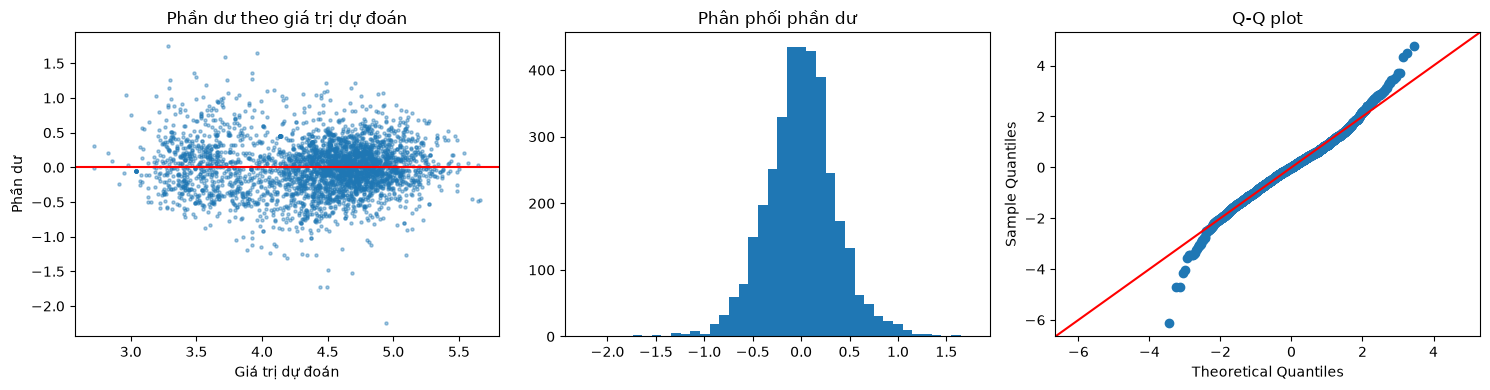

Trung bình phần dư: 0.0
Số dòng có |phần dư| > 1: 58


In [6]:
import matplotlib.pyplot as plt

phan_du = mo_hinh_ols.resid               # phần dư = giá thật - giá dự đoán
gia_tri_du_doan = mo_hinh_ols.fittedvalues

fig, truc = plt.subplots(1, 3, figsize=(15, 4))

# Biểu đồ 1: phần dư theo giá trị dự đoán (nên rải đều quanh đường 0)
truc[0].scatter(gia_tri_du_doan, phan_du, s=5, alpha=0.4)
truc[0].axhline(0, color="red")
truc[0].set_xlabel("Giá trị dự đoán")
truc[0].set_ylabel("Phần dư")
truc[0].set_title("Phần dư theo giá trị dự đoán")

# Biểu đồ 2: phân phối phần dư (nên có hình chuông, đỉnh ở 0)
truc[1].hist(phan_du, bins=40)
truc[1].set_title("Phân phối phần dư")

# Biểu đồ 3: Q-Q plot (các điểm càng sát đường đỏ thì phần dư càng gần phân phối chuẩn)
sm.qqplot(phan_du, line="45", fit=True, ax=truc[2])
truc[2].set_title("Q-Q plot")

plt.tight_layout()
plt.show()

print("Trung bình phần dư:", round(phan_du.mean(), 4))
print("Số dòng có |phần dư| > 1:", (phan_du.abs() > 1).sum())

In [7]:
# Bảng hệ số để đưa vào báo cáo (bỏ hằng số)
bang_he_so = pd.DataFrame({
    "He_so": mo_hinh_ols.params,
    "P_value": mo_hinh_ols.pvalues
}).drop("const")

# Đổi hệ số sang "% thay đổi giá/m2" (vì biến mục tiêu là log)
bang_he_so["Thay_doi_gia_m2_%"] = ((np.exp(bang_he_so["He_so"]) - 1) * 100).round(1)
bang_he_so = bang_he_so.round(4)

bang_he_so.to_csv("../report/ols_he_so.csv", encoding="utf-8-sig")

# Lưu hình phần dư (biến fig lấy từ ô 6)
fig.savefig("../report/ols_phan_du.png", dpi=150, bbox_inches="tight")

bang_he_so

,He_so,P_value,Thay_doi_gia_m2_%
Area,-0.0008,0.0000,-0.1
Width,-0.0022,0.1576,-0.2
Length,-0.0015,0.0112,-0.1
Bedrooms,0.0020,0.2517,0.2
Floors,0.1334,0.0000,14.3
Dist_BenThanh_km,-0.0602,0.0000,-5.8
Dist_Metro_km,-0.0050,0.0384,-0.5
Position_Trong hẻm,-0.2203,0.0000,-19.8
Position_Đường chính,-0.0321,0.0384,-3.2
